In [1]:
import pandas as pd
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
df.shape

(768, 9)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:

df.nunique()

Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
dtype: int64

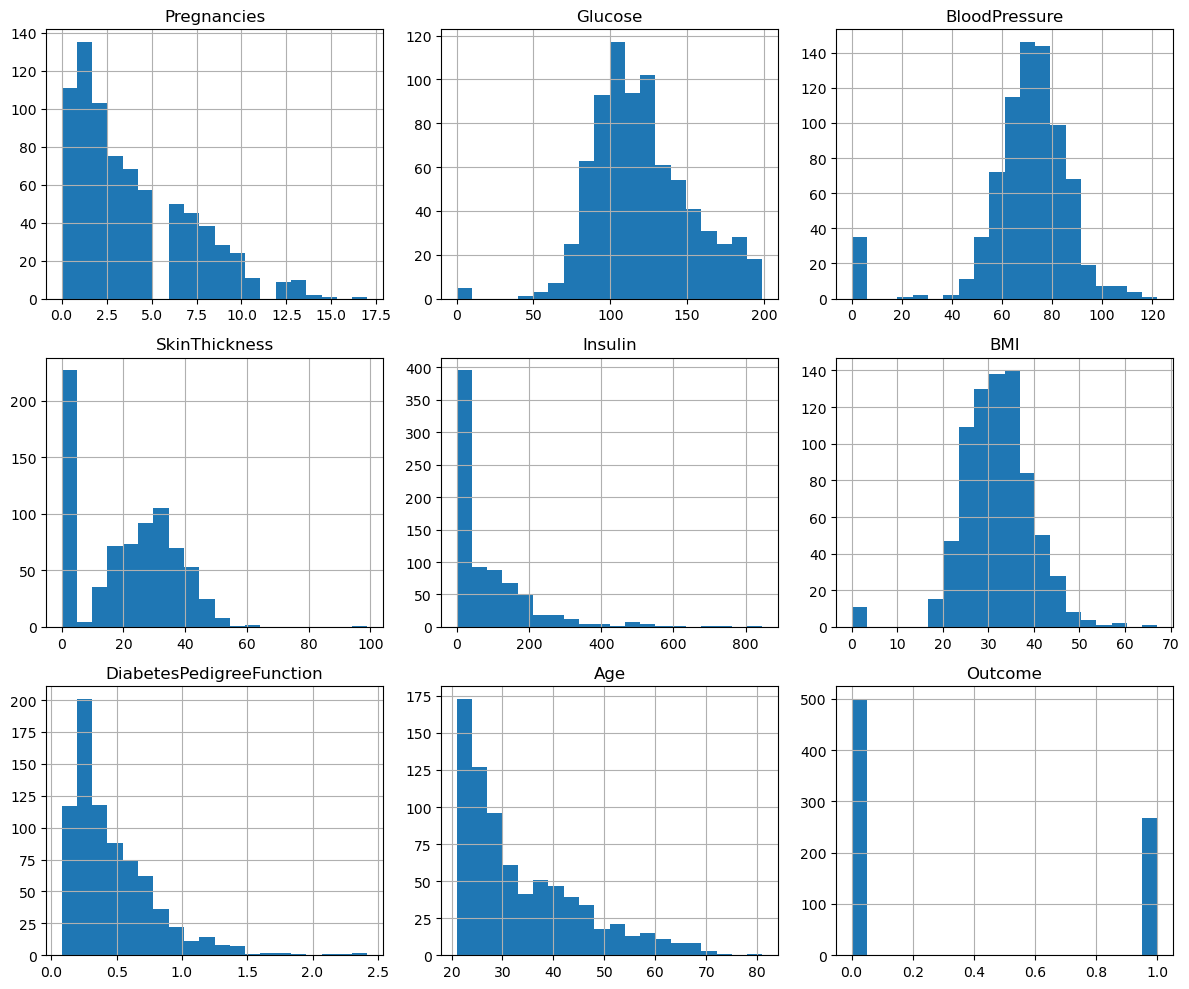

In [8]:
import matplotlib.pyplot as plt
df.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

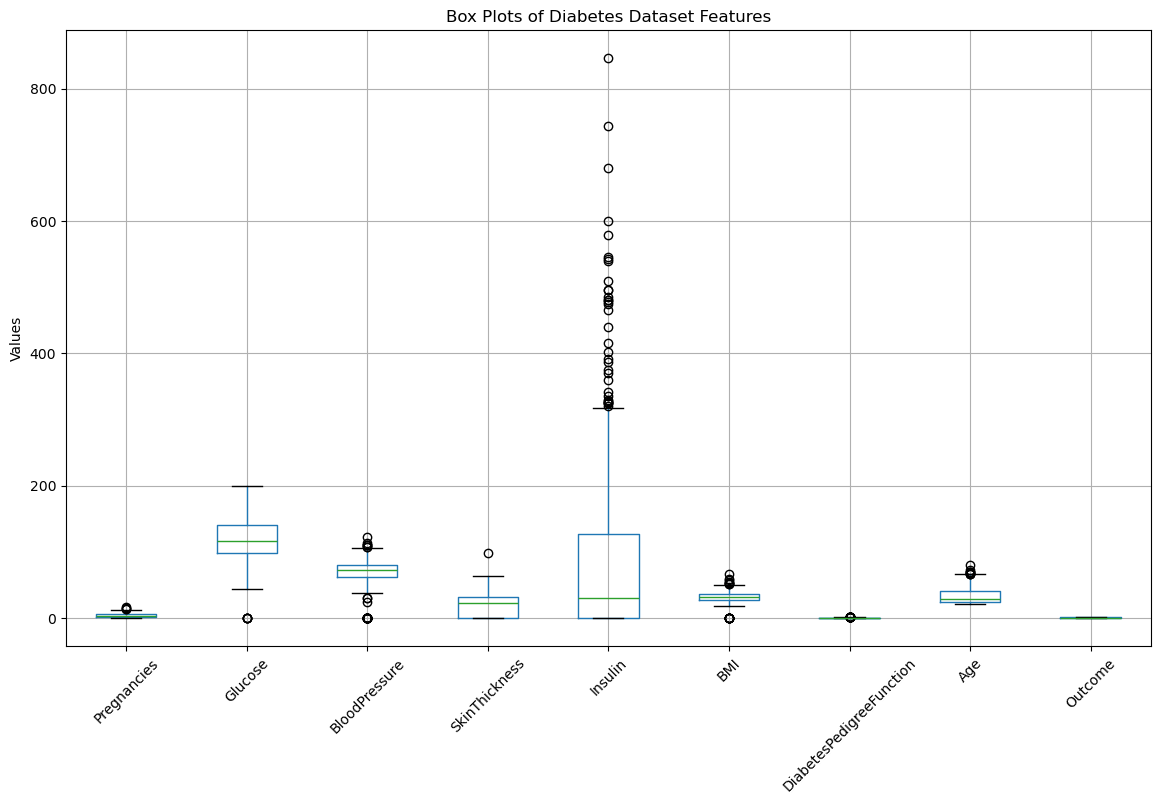

In [9]:
plt.figure(figsize=(14, 8))
df.boxplot()
plt.xticks(rotation=45)
plt.title("Box Plots of Diabetes Dataset Features")
plt.ylabel("Values")
plt.show()

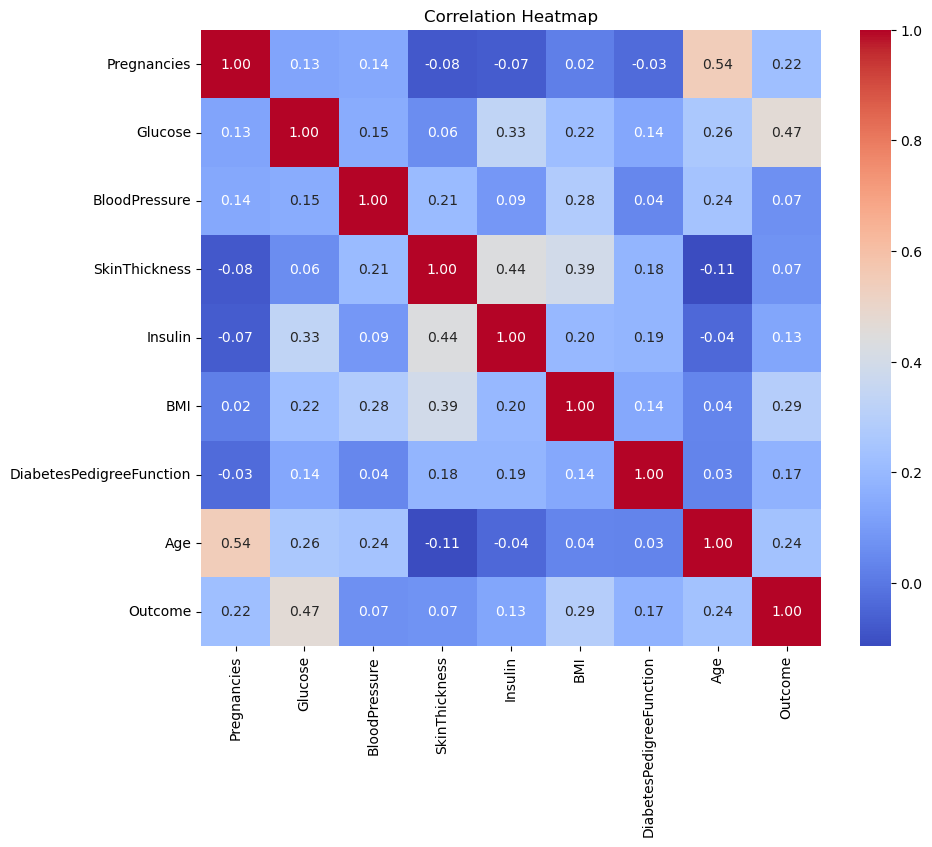

In [10]:
import seaborn as sns
correlation = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

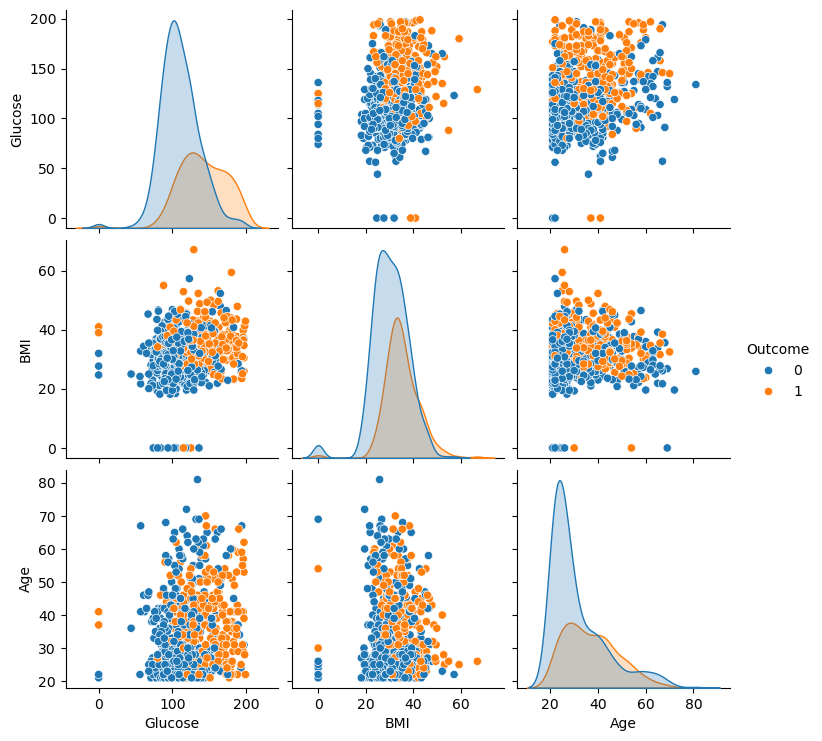

In [11]:
selected_features = [
    "Glucose",
    "BMI",
    "Age",
    "Outcome"
]
sns.pairplot(
    df[selected_features],
    hue="Outcome"
)
plt.show()

In [12]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [13]:
print(y.value_counts())
print("\nClass proportions:")
print(y.value_counts(normalize=True))

Outcome
0    500
1    268
Name: count, dtype: int64

Class proportions:
Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


In [14]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.639947,0.848324,0.149641,0.907270,-0.692891,0.204013,0.468492,1.425995
1,-0.844885,-1.123396,-0.160546,0.530902,-0.692891,-0.684422,-0.365061,-0.190672
2,1.233880,1.943724,-0.263941,-1.288212,-0.692891,-1.103255,0.604397,-0.105584
3,-0.844885,-0.998208,-0.160546,0.154533,0.123302,-0.494043,-0.920763,-1.041549
4,-1.141852,0.504055,-1.504687,0.907270,0.765836,1.409746,5.484909,-0.020496


In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (614, 8)
X_test shape: (154, 8)
y_train shape: (614,)
y_test shape: (154,)


In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (614, 8)
X_test_scaled shape: (154, 8)


In [17]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(random_state=42)
logistic_model.fit(X_train_scaled, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [18]:
y_pred = logistic_model.predict(X_test_scaled)
print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[1 0 0 0 0 0 0 1 0 1]


In [19]:
y_prob = logistic_model.predict_proba(X_test_scaled)
print(y_prob[:5])

[[0.38332647 0.61667353]
 [0.88721884 0.11278116]
 [0.72746042 0.27253958]
 [0.71331836 0.28668164]
 [0.99551857 0.00448143]]


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.7142857142857143
Precision: 0.6086956521739131
Recall   : 0.5185185185185185
F1-score : 0.56


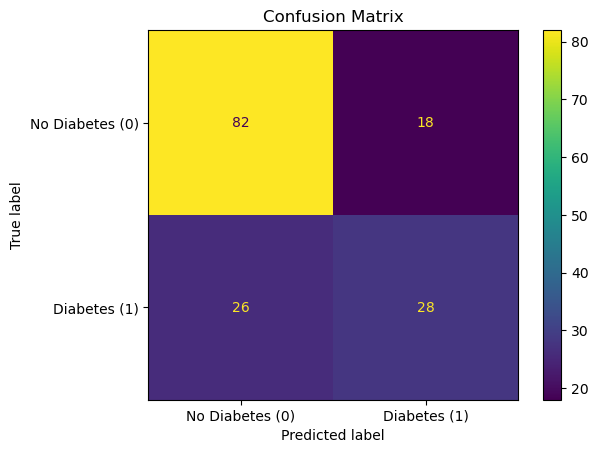

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes (0)", "Diabetes (1)"]
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()

In [22]:
from sklearn.metrics import roc_auc_score, roc_curve
y_prob_positive = y_prob[:, 1]
roc_auc = roc_auc_score(y_test, y_prob_positive)
print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8229629629629629


In [23]:
from sklearn.metrics import roc_auc_score, roc_curve
y_prob_positive = y_prob[:, 1]
roc_auc = roc_auc_score(y_test, y_prob_positive)
print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8229629629629629


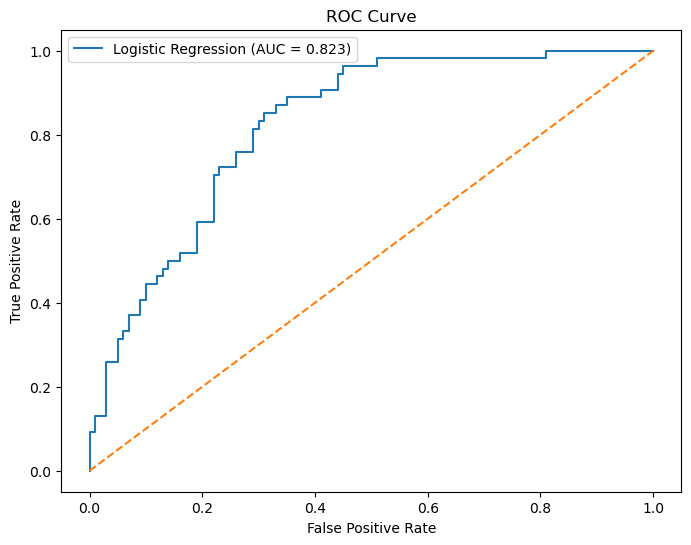

In [24]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_positive)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [25]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})
coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=True
)
coefficients

,Feature,Coefficient
2,BloodPressure,-0.197637
4,Insulin,-0.127308
3,SkinThickness,0.066535
7,Age,0.184179
6,DiabetesPedigreeFunction,0.255527
0,Pregnancies,0.373178
5,BMI,0.713893
1,Glucose,1.144151


In [26]:
import numpy as np
coefficients["Odds_Ratio"] = np.exp(coefficients["Coefficient"])
coefficients

,Feature,Coefficient,Odds_Ratio
2,BloodPressure,-0.197637,0.820668
4,Insulin,-0.127308,0.880462
3,SkinThickness,0.066535,1.068798
7,Age,0.184179,1.202231
6,DiabetesPedigreeFunction,0.255527,1.291142
0,Pregnancies,0.373178,1.452343
5,BMI,0.713893,2.041926
1,Glucose,1.144151,3.139775


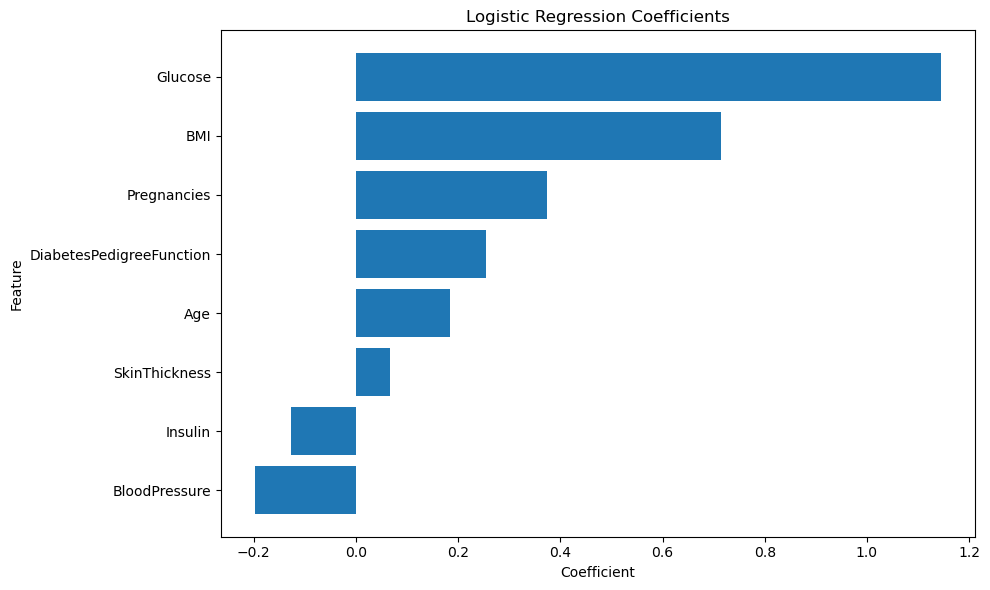

In [27]:
# Create a horizontal bar chart of the Logistic Regression coefficients
plt.figure(figsize=(10, 6))

plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Logistic Regression Coefficients")

plt.tight_layout()
plt.show()

In [28]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})
final_results

,Metric,Score
0,Accuracy,0.714286
1,Precision,0.608696
2,Recall,0.518519
3,F1-Score,0.560000
4,ROC-AUC,0.822963


In [29]:
final_results["Score"] = final_results["Score"].round(3)
final_results

,Metric,Score
0,Accuracy,0.714
1,Precision,0.609
2,Recall,0.519
3,F1-Score,0.560
4,ROC-AUC,0.823


In [30]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"]
))

              precision    recall  f1-score   support

 No Diabetes       0.76      0.82      0.79       100
    Diabetes       0.61      0.52      0.56        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154



In [31]:
import joblib
joblib.dump(logistic_model, "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Model and scaler saved successfully.")

Model and scaler saved successfully.


In [32]:

import os

print(os.listdir())

['.ipynb_checkpoints', '11-06-26.ipynb', '15-06-.ipynb', '16-06-26.ipynb', 'adult_with_headers (1).csv', 'advertising (1).csv', 'anime.csv', 'banking_dataset.csv', 'Basics Stats - 1.ipynb', 'Basics stats -2.ipynb', 'Basics_of_python.ipynb', 'Billing_Data (1).csv', 'Billing_Data.csv', 'Bulbs_Lifespan.csv', 'Cardiotocographic.csv', 'Cars_4vars.csv', 'Classification.ipynb', 'Clustering ana.ipynb', 'conditional_statements_looping.ipynb', 'Data Structures, Functions, numpy and pandas .ipynb', 'Data Transformation.ipynb', 'Decision Tree final.ipynb', 'diabetes (1).csv', 'diabetes.csv', 'EastWestAirlines.xlsx', 'ecommerce_two_sample_ztest_dataset.csv', 'EDA.ipynb', 'exchange_rate.csv', 'experience_vs_salary.csv', 'first_file.csv', 'glass.xlsx', 'heart_disease.xlsx', 'Hypothesis_testing.ipynb', 'Indexing&slicing.ipynb', 'inferential_stats.ipynb', 'LgRegression.ipynb', 'logistic_regression_model.pkl', 'LR12fina.ipynb', 'market.csv', 'MLR.ipynb', 'nyc_weather.csv', 'Pandas.ipynb', 'Patient_Data 

In [33]:
import os

print(os.getcwd())

C:\Users\AKSHAY\DataScience


In [34]:
import joblib
joblib.dump(logistic_model, "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Both files saved successfully!")

Both files saved successfully!


In [35]:
joblib.dump(logistic_model, "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [36]:
import os

print(os.listdir())

['.ipynb_checkpoints', '11-06-26.ipynb', '15-06-.ipynb', '16-06-26.ipynb', 'adult_with_headers (1).csv', 'advertising (1).csv', 'anime.csv', 'banking_dataset.csv', 'Basics Stats - 1.ipynb', 'Basics stats -2.ipynb', 'Basics_of_python.ipynb', 'Billing_Data (1).csv', 'Billing_Data.csv', 'Bulbs_Lifespan.csv', 'Cardiotocographic.csv', 'Cars_4vars.csv', 'Classification.ipynb', 'Clustering ana.ipynb', 'conditional_statements_looping.ipynb', 'Data Structures, Functions, numpy and pandas .ipynb', 'Data Transformation.ipynb', 'Decision Tree final.ipynb', 'diabetes (1).csv', 'diabetes.csv', 'EastWestAirlines.xlsx', 'ecommerce_two_sample_ztest_dataset.csv', 'EDA.ipynb', 'exchange_rate.csv', 'experience_vs_salary.csv', 'first_file.csv', 'glass.xlsx', 'heart_disease.xlsx', 'Hypothesis_testing.ipynb', 'Indexing&slicing.ipynb', 'inferential_stats.ipynb', 'LgRegression.ipynb', 'logistic_regression_model.pkl', 'LR12fina.ipynb', 'market.csv', 'MLR.ipynb', 'nyc_weather.csv', 'Pandas.ipynb', 'Patient_Data 

In [37]:
import joblib
joblib.dump(logistic_model, "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Both files saved successfully!")

Both files saved successfully!


In [38]:
print(os.getcwd())

C:\Users\AKSHAY\DataScience


In [39]:
import os

print("Desktop folders:")
print(os.listdir(r"C:\Users\AKSHAY\DataScience"))

Desktop folders:
['.ipynb_checkpoints', '11-06-26.ipynb', '15-06-.ipynb', '16-06-26.ipynb', 'adult_with_headers (1).csv', 'advertising (1).csv', 'anime.csv', 'banking_dataset.csv', 'Basics Stats - 1.ipynb', 'Basics stats -2.ipynb', 'Basics_of_python.ipynb', 'Billing_Data (1).csv', 'Billing_Data.csv', 'Bulbs_Lifespan.csv', 'Cardiotocographic.csv', 'Cars_4vars.csv', 'Classification.ipynb', 'Clustering ana.ipynb', 'conditional_statements_looping.ipynb', 'Data Structures, Functions, numpy and pandas .ipynb', 'Data Transformation.ipynb', 'Decision Tree final.ipynb', 'diabetes (1).csv', 'diabetes.csv', 'EastWestAirlines.xlsx', 'ecommerce_two_sample_ztest_dataset.csv', 'EDA.ipynb', 'exchange_rate.csv', 'experience_vs_salary.csv', 'first_file.csv', 'glass.xlsx', 'heart_disease.xlsx', 'Hypothesis_testing.ipynb', 'Indexing&slicing.ipynb', 'inferential_stats.ipynb', 'LgRegression.ipynb', 'logistic_regression_model.pkl', 'LR12fina.ipynb', 'market.csv', 'MLR.ipynb', 'nyc_weather.csv', 'Pandas.ipynb

In [40]:
import os

# Create the Streamlit project folder on Desktop
project_path = r"C:\Users\AKSHAY\Desktop\Diabetes_Project"

os.makedirs(project_path, exist_ok=True)

print("Created successfully:")
print(project_path)

Created successfully:
C:\Users\AKSHAY\Desktop\Diabetes_Project


In [41]:
import os

print("Current notebook folder:")
print(os.getcwd())

print("\nFiles in current folder:")
print(os.listdir())

Current notebook folder:
C:\Users\AKSHAY\DataScience

Files in current folder:
['.ipynb_checkpoints', '11-06-26.ipynb', '15-06-.ipynb', '16-06-26.ipynb', 'adult_with_headers (1).csv', 'advertising (1).csv', 'anime.csv', 'banking_dataset.csv', 'Basics Stats - 1.ipynb', 'Basics stats -2.ipynb', 'Basics_of_python.ipynb', 'Billing_Data (1).csv', 'Billing_Data.csv', 'Bulbs_Lifespan.csv', 'Cardiotocographic.csv', 'Cars_4vars.csv', 'Classification.ipynb', 'Clustering ana.ipynb', 'conditional_statements_looping.ipynb', 'Data Structures, Functions, numpy and pandas .ipynb', 'Data Transformation.ipynb', 'Decision Tree final.ipynb', 'diabetes (1).csv', 'diabetes.csv', 'EastWestAirlines.xlsx', 'ecommerce_two_sample_ztest_dataset.csv', 'EDA.ipynb', 'exchange_rate.csv', 'experience_vs_salary.csv', 'first_file.csv', 'glass.xlsx', 'heart_disease.xlsx', 'Hypothesis_testing.ipynb', 'Indexing&slicing.ipynb', 'inferential_stats.ipynb', 'LgRegression.ipynb', 'logistic_regression_model.pkl', 'LR12fina.ipynb

In [42]:
import shutil
import os

project_folder = r"C:\Users\AKSHAY\Desktop\Diabetes_Project"

os.makedirs(project_folder, exist_ok=True)

shutil.copy(
    "logistic_regression_model.pkl",
    project_folder
)

shutil.copy(
    "scaler.pkl",
    project_folder
)

print("Both files copied successfully!")

Both files copied successfully!


In [43]:
import joblib
import os

project_folder = r"C:\Users\AKSHAY\Desktop\Diabetes_Project"

os.makedirs(project_folder, exist_ok=True)

joblib.dump(
    logistic_model,
    os.path.join(project_folder, "logistic_regression_model.pkl")
)

joblib.dump(
    scaler,
    os.path.join(project_folder, "scaler.pkl")
)

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [44]:
print(os.listdir(project_folder))

['logistic_regression_model.pkl', 'scaler.pkl']


In [50]:
import os

project_folder = r"C:\Users\AKSHAY\Desktop\Diabetes_Project"

print(os.listdir(project_folder))

['logistic_regression_model.pkl', 'scaler.pkl']


In [47]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})
final_results

,Metric,Score
0,Accuracy,0.714286
1,Precision,0.608696
2,Recall,0.518519
3,F1-Score,0.560000
4,ROC-AUC,0.822963


In [48]:
final_results["Score"] = final_results["Score"].round(3)
final_results

,Metric,Score
0,Accuracy,0.714
1,Precision,0.609
2,Recall,0.519
3,F1-Score,0.560
4,ROC-AUC,0.823


In [50]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"]
))

              precision    recall  f1-score   support

 No Diabetes       0.76      0.82      0.79       100
    Diabetes       0.61      0.52      0.56        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154



In [51]:
import joblib
joblib.dump(logistic_model, "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Model and scaler saved successfully.")

Model and scaler saved successfully.


In [52]:

import os

print(os.listdir())

['.ipynb_checkpoints', '11-06-26.ipynb', '15-06-.ipynb', '16-06-26.ipynb', 'adult_with_headers (1).csv', 'advertising (1).csv', 'anime.csv', 'banking_dataset.csv', 'Basics Stats - 1.ipynb', 'Basics stats -2.ipynb', 'Basics_of_python.ipynb', 'Billing_Data (1).csv', 'Billing_Data.csv', 'Bulbs_Lifespan.csv', 'Cardiotocographic.csv', 'Cars_4vars.csv', 'Classification.ipynb', 'Clustering ana.ipynb', 'conditional_statements_looping.ipynb', 'Data Structures, Functions, numpy and pandas .ipynb', 'Data Transformation.ipynb', 'Decision Tree final.ipynb', 'diabetes (1).csv', 'diabetes.csv', 'EastWestAirlines.xlsx', 'ecommerce_two_sample_ztest_dataset.csv', 'EDA.ipynb', 'exchange_rate.csv', 'experience_vs_salary.csv', 'first_file.csv', 'glass.xlsx', 'heart_disease.xlsx', 'Hypothesis_testing.ipynb', 'Indexing&slicing.ipynb', 'inferential_stats.ipynb', 'LgRegression.ipynb', 'logistic_regression_model.pkl', 'LR12fina.ipynb', 'market.csv', 'MLR.ipynb', 'nyc_weather.csv', 'Pandas.ipynb', 'Patient_Data 

In [53]:
import os

print(os.getcwd())

C:\Users\AKSHAY\DataScience


In [55]:
import joblib
joblib.dump(logistic_model, "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Both files saved successfully!")

Both files saved successfully!


In [49]:
# ## Interview Questions

# ### 1. What is the difference between Precision and Recall?

# Precision tells us how many of the observations predicted as positive are actually positive.

# Recall tells us how many of the actual positive observations were correctly identified by the model.

# In simple terms, Precision focuses on the correctness of positive predictions, while Recall focuses on identifying as many actual positive cases as possible.

# ---

# ### 2. What is Cross-Validation, and why is it important in Binary Classification?

# Cross-validation is a technique used to evaluate how well a machine learning model performs on unseen data. The dataset is divided into multiple parts (folds), and the model is trained and tested multiple times using different folds.

# It is important in binary classification because it provides a more reliable estimate of model performance and helps identify whether the model is overfitting or underfitting.

# Cross-validation helps ensure that the model performs consistently on different portions of the dataset.

## Streamlit Deployment

The following cells export the fitted Logistic Regression model and scaler. Then use the `app.py` and `requirements.txt` files supplied with this notebook to run and deploy the application.


In [ ]:
import joblib

joblib.dump(logistic_model, "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Exported logistic_regression_model.pkl and scaler.pkl")


### Run the Streamlit application

1. Copy `logistic_regression_model.pkl` and `scaler.pkl` into the folder containing `app.py`.
2. Install dependencies with `python -m pip install -r requirements.txt`.
3. Start the app with `python -m streamlit run app.py`.
4. For online deployment, push the four files (`app.py`, `requirements.txt`, and both `.pkl` files) to a GitHub repository and deploy the repository using Streamlit Community Cloud.
5. Add the deployed app URL to your assignment submission.
